# 06 · Classification: will the customer buy again in the next 6 months?

**Business question:** *which customers are likely to go quiet, so we can decide who gets a retention offer?*
This is the first half of the value model: `y_buy` (0/1). Notebook 07 does the "how much" half.

**What this notebook decides:**
1. **Which classifier:** logistic regression (notebook 05's pipeline) vs. LightGBM, against the naive bar (AUC ≈ 0.72 mean, 0.75 in Dec).
2. **Can we trust the probabilities?** Ranking (AUC) and calibration (log loss, Brier, calibration curve) are different questions.
3. **Where to draw the line:** a decision threshold derived from **business cost**, not from 0.5.

### Metrics and what each one answers
| Metric | Question | Note |
|---|---|---|
| ROC-AUC | Are buyers ranked above non-buyers? | the lead metric for model choice; ignores probability levels |
| PR-AUC | Among the top-ranked, how pure are the buyers? | its baseline = the buy rate, which differs by fold, so compare models *within* a fold |
| Log loss | Are probabilities right, punishing confident mistakes hard? | sensitive to calibration |
| Brier | Mean squared error of the probabilities | calibration + sharpness, gentler than log loss |

**Class balance:** buy rate is 72% in training and 46–64% across validation folds. That's mild imbalance, so **no resampling or class weights**.
Both would change the predicted probabilities without improving the ranking. Cost asymmetry is handled where it belongs: in the **threshold** (section 4).

### 🧠 Predict first
1. Will LightGBM beat logistic regression? By how much?
2. The model is trained on cutoffs with a 72% buy rate and validated in December (46%). What will its **average predicted probability** be in December?
3. If a retention offer costs £20 and saves 20% of customers who would otherwise lapse, should the threshold on P(buy) be above or below 0.5?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss
from sklearn.calibration import calibration_curve

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET
from src.split import TRAIN_CUTOFFS, MARGIN, time_folds, monthly_cutoffs
from src.models import make_logreg, make_lgbm_classifier, run_folds, per_fold, LGBM_BASE

pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

table = pd.read_parquet(Path(CLEAN_PARQUET).parent / "features.parquet")
FOLDS = time_folds(monthly_cutoffs("2010-09", "2010-12"))

## 1. Three classifiers on four time folds
- **Naive score:** `spend_180d` (no training), the bar from notebook 03.
- **Logistic regression:** notebook 05's pipeline (median fill, scaling, `is_uk`).
- **LightGBM, default-ish:** 31 leaves, 20 rows per leaf, learning rate 0.1. The settings people use when they don't think about data size.
- **LightGBM, regularised:** 15 leaves, ≥ 100 rows per leaf, row and column subsampling, L2 penalty, learning rate 0.03.
  It's sized for about 2.8k distinct customers, not for the about 11k correlated rows (proper tuning in notebook 08).

In [2]:
naive = pd.concat([table.loc[table["cutoff"] == v, ["Customer ID", "y_buy", "spend_180d"]]
                   .rename(columns={"y_buy": "y", "spend_180d": "pred"}).assign(fold=v.strftime("%b"), cutoff=v) for _, v in FOLDS])
lgbm_default = dict(n_estimators=100, learning_rate=0.1, num_leaves=31, min_child_samples=20,
                    subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0)
preds = {
    "naive (spend_180d)": naive,
    "logistic regression": run_folds(table, make_logreg, "y_buy", FOLDS),
    "LightGBM default-ish": run_folds(table, lambda: make_lgbm_classifier(**lgbm_default), "y_buy", FOLDS),
    "LightGBM regularised": run_folds(table, make_lgbm_classifier, "y_buy", FOLDS),
}
auc = pd.DataFrame({k: per_fold(p, roc_auc_score) for k, p in preds.items()}).T
pr = pd.DataFrame({k: per_fold(p, average_precision_score) for k, p in preds.items()}).T
print("ROC-AUC by validation fold"); display(auc.round(4))
print("PR-AUC by validation fold (baseline = buy rate:",
      {f: round(d["y"].mean(), 2) for f, d in preds["naive (spend_180d)"].groupby("fold", sort=False)}, ")")
display(pr.round(4))

ROC-AUC by validation fold


,Sep,Oct,Nov,Dec,mean
naive (spend_180d),0.7058,0.7098,0.7242,0.7518,0.7229
logistic regression,0.7359,0.7411,0.7570,0.7812,0.7538
LightGBM default-ish,0.6967,0.7101,0.7264,0.7600,0.7233
LightGBM regularised,0.7104,0.7207,0.7377,0.7709,0.7349


PR-AUC by validation fold (baseline = buy rate: {'Sep': np.float64(0.64), 'Oct': np.float64(0.6), 'Nov': np.float64(0.53), 'Dec': np.float64(0.46)} )


,Sep,Oct,Nov,Dec,mean
naive (spend_180d),0.7964,0.7859,0.7509,0.7329,0.7665
logistic regression,0.8362,0.8294,0.8035,0.7793,0.8121
LightGBM default-ish,0.8132,0.8019,0.7730,0.7597,0.7870
LightGBM regularised,0.8225,0.8087,0.7834,0.7657,0.7951


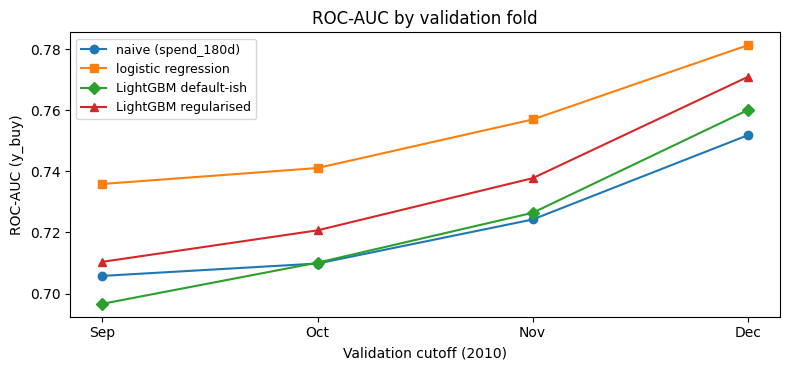

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for (name, row), m in zip(auc.drop(columns="mean").iterrows(), "osD^"):
    ax.plot(row.index, row.values, marker=m, label=name)
ax.set_title("ROC-AUC by validation fold")
ax.set_xlabel("Validation cutoff (2010)")
ax.set_ylabel("ROC-AUC (y_buy)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Takeaways:**
- **Logistic regression is best in every fold** (mean AUC ≈ 0.754 vs. 0.735 for regularised LightGBM and 0.72 for the naive score).
- **Regularising LightGBM matters:** the default-ish version barely beats the naive score; shrinking the trees adds about 0.01 in every fold.
- **Why can a simple linear model beat a GBM here?** (hypotheses to test in 08)
  1. **Little data:** about 2.8k customers. GBMs shine with lots of rows and real interactions.
  2. **Mostly monotone, additive signal:** "more spend, more frequency, more recent → more likely" is what logistic regression is built for.
  3. **Distribution shift:** training rows have short histories, validation rows long ones. Trees learn sharp, step-shaped rules tuned to the training range and can't extrapolate.
     A linear model's smooth trend degrades more gracefully.
- **Interview line:** *"I didn't assume the GBM would win. On ~3k customers with mostly monotone signal and a train/validation shift, a regularised logistic regression beat it in every time fold."*

### Is the gap real? A paired bootstrap on the December fold
Both models score the **same** customers, so we resample customers and recompute the **difference** each time. A paired comparison removes the noise that's common to both models.

In [4]:
def paired_auc_diff(a: pd.DataFrame, b: pd.DataFrame, n_boot: int = 1000) -> tuple:
    a, b = a.sort_values("Customer ID"), b.sort_values("Customer ID")
    assert (a["Customer ID"].values == b["Customer ID"].values).all()
    y, pa, pb = a["y"].values, a["pred"].values, b["pred"].values
    rng = np.random.default_rng(SEED)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        diffs.append(roc_auc_score(y[i], pa[i]) - roc_auc_score(y[i], pb[i]))
    return roc_auc_score(y, pa) - roc_auc_score(y, pb), *np.quantile(diffs, [0.025, 0.975])


dec = {k: p[p["fold"] == "Dec"] for k, p in preds.items()}
for a, b in [("logistic regression", "LightGBM regularised"), ("logistic regression", "naive (spend_180d)"),
             ("LightGBM regularised", "naive (spend_180d)")]:
    d, lo, hi = paired_auc_diff(dec[a], dec[b])
    print(f"Dec: {a:<22} − {b:<22} = {d:+.4f}   95% CI [{lo:+.4f}, {hi:+.4f}]")

Dec: logistic regression    − LightGBM regularised   = +0.0104   95% CI [+0.0035, +0.0167]


Dec: logistic regression    − naive (spend_180d)     = +0.0294   95% CI [+0.0188, +0.0386]


Dec: LightGBM regularised   − naive (spend_180d)     = +0.0191   95% CI [+0.0098, +0.0278]


**Takeaway:** in December, logistic regression beats both LightGBM and the naive score with confidence intervals that **exclude zero**. Combined with "wins in all 4 folds", that's a real difference, not noise.
Note how much **tighter** the paired CIs are than the unpaired ones from notebook 03 (± about 0.015). Pairing is the right way to compare two models on the same data.

## 2. Can we trust the probabilities? Calibration
AUC says nothing about whether "70%" means 70%. For budgeting ("how many customers will we lose?") and for cost-based thresholds, **the levels matter**.

In [5]:
calib = pd.DataFrame({k: {**{f"{f} pred": d["pred"].mean() for f, d in p.groupby("fold", sort=False)},
                          "log_loss": per_fold(p, log_loss)["mean"], "brier": per_fold(p, brier_score_loss)["mean"]}
                      for k, p in preds.items() if not k.startswith("naive")}).T
actual = {f"{f} actual": d["y"].mean() for f, d in preds["logistic regression"].groupby("fold", sort=False)}
print("Actual buy rate per fold:", {k: round(v, 3) for k, v in actual.items()})
calib.round(3)

Actual buy rate per fold: {'Sep actual': np.float64(0.635), 'Oct actual': np.float64(0.602), 'Nov actual': np.float64(0.534), 'Dec actual': np.float64(0.464)}


,Sep pred,Oct pred,Nov pred,Dec pred,log_loss,brier
logistic regression,0.736,0.731,0.748,0.761,0.758,0.242
LightGBM default-ish,0.693,0.697,0.715,0.771,0.752,0.253
LightGBM regularised,0.686,0.693,0.701,0.752,0.682,0.237


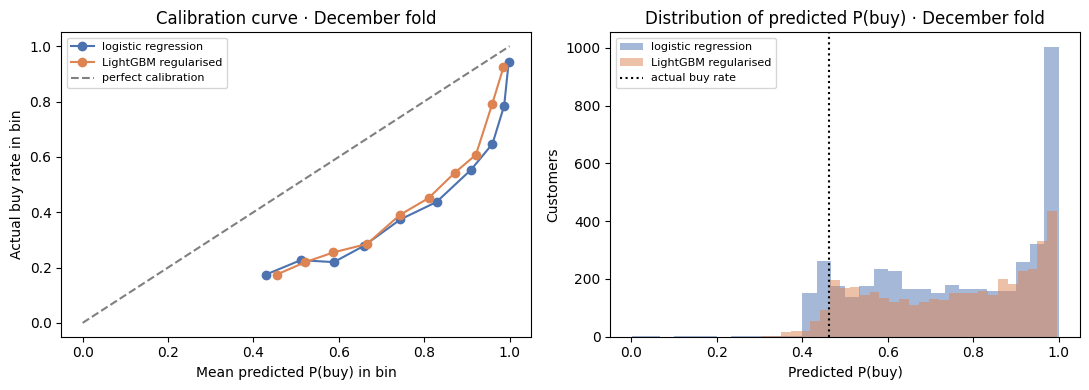

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, color in [("logistic regression", "#4C72B0"), ("LightGBM regularised", "#DD8452")]:
    d = dec[name]
    frac_pos, mean_pred = calibration_curve(d["y"], d["pred"], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, marker="o", color=color, label=name)
    axes[1].hist(d["pred"], bins=30, alpha=0.5, color=color, label=name)
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", label="perfect calibration")
axes[0].set_title("Calibration curve · December fold")
axes[0].set_xlabel("Mean predicted P(buy) in bin")
axes[0].set_ylabel("Actual buy rate in bin")
axes[0].legend(fontsize=8)
axes[1].axvline(dec["logistic regression"]["y"].mean(), color="black", ls=":", label="actual buy rate")
axes[1].set_title("Distribution of predicted P(buy) · December fold")
axes[1].set_xlabel("Predicted P(buy)")
axes[1].set_ylabel("Customers")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Takeaway:** both models are **systematically over-confident about buying**. In December they predict an average P(buy) ≈ 0.75–0.76 when the real rate is 0.46, and the whole calibration curve sits below the diagonal.
This is the base-rate shift from notebook 02, now inside the model: it learned "about 72% of customers buy again" from spring/summer cutoffs whose windows include Christmas.

LightGBM has a better log loss and Brier score here despite the worse AUC. **Better ranking and better probabilities can belong to different models.**
Look at the right panel: logistic regression piles about 1,000 customers at P(buy) ≈ 1.0. With raw-scale (un-logged) features, a very large spender pushes the linear score to an extreme and the sigmoid saturates.
That's harmless for ranking but expensive for log loss: one confident miss costs a lot. It's a trade-off of notebook 05's "no log transform" decision, visible only in the probabilities.

### Can we fix the level? Prior-shift correction
If the *relationship* between features and buying is stable and only the overall rate moves (**label shift**), we can shift every prediction's log-odds by the change in base rate:

$$\text{logit}(p_{new}) = \text{logit}(p) + \text{logit}(\pi_{new}) - \text{logit}(\pi_{train})$$

The catch: we need $\pi_{new}$, the buy rate we *expect* in the new window. Options in practice:
- **Same season last year.** At the **test** cutoff (June 2011), the June 2010 cutoff's rate (71%) is known and comes from the same season. ✅ Usable in notebook 12.
- At the **December** validation cutoff, the same-season analogue would be December 2009, before the data starts. ❌ Not available.
- So below we use the actual December rate as an **oracle**, to see the *best case* of the correction, not as a fair evaluation.

In [7]:
def prior_shift(p, pi_train: float, pi_new: float):
    logit = lambda x: np.log(x / (1 - x))
    z = logit(np.clip(p, 1e-6, 1 - 1e-6)) + logit(pi_new) - logit(pi_train)
    return 1 / (1 + np.exp(-z))


pi_train = table.loc[table["cutoff"].isin(TRAIN_CUTOFFS), "y_buy"].mean()
lr_dec = dec["logistic regression"].copy()
pi_dec = lr_dec["y"].mean()
lr_dec["pred_shifted"] = prior_shift(lr_dec["pred"], pi_train, pi_dec)

pd.DataFrame({
    "raw": {"mean P(buy)": lr_dec["pred"].mean(), "log_loss": log_loss(lr_dec["y"], lr_dec["pred"]),
            "brier": brier_score_loss(lr_dec["y"], lr_dec["pred"]), "AUC": roc_auc_score(lr_dec["y"], lr_dec["pred"])},
    "prior-shifted (oracle rate)": {"mean P(buy)": lr_dec["pred_shifted"].mean(), "log_loss": log_loss(lr_dec["y"], lr_dec["pred_shifted"]),
                                    "brier": brier_score_loss(lr_dec["y"], lr_dec["pred_shifted"]), "AUC": roc_auc_score(lr_dec["y"], lr_dec["pred_shifted"])},
}).T.round(4)

,mean P(buy),log_loss,brier,AUC
raw,0.7615,0.8666,0.2855,0.7812
prior-shifted (oracle rate),0.5882,0.6297,0.2073,0.7812


**Takeaway:** even with the *true* December rate, the shift only moves the average prediction from 0.76 to 0.59 (truth: 0.46), about 60% of the way. It does cut log loss (0.87 → 0.63) and Brier (0.29 → 0.21), and **AUC is unchanged** (a monotone transform doesn't change the ranking).
Why only part of the way? The formula assumes *only* the base rate moved (label shift). Here the relationship moved too: e.g. a one-day buyer means something different in December (notebook 05).
So treat the prior shift as a **first-order fix**, not a full recalibration.
So the decomposition is clean:
- **Ranking** comes from the model and transfers across seasons.
- **Level** comes from the base rate and must be supplied by a seasonal estimate.

That's the plan for deployment: *rank with the model, set the level with a same-season prior.*

## 3. Picking the model

In [8]:
summary = pd.DataFrame({
    "mean AUC (4 folds)": auc["mean"],
    "Dec AUC": auc["Dec"],
    "mean log loss": [np.nan] + [per_fold(preds[k], log_loss)["mean"] for k in list(preds)[1:]],
}, index=auc.index)
summary.round(4)

,mean AUC (4 folds),Dec AUC,mean log loss
naive (spend_180d),0.7229,0.7518,NaN
logistic regression,0.7538,0.7812,0.7580
LightGBM default-ish,0.7233,0.7600,0.7525
LightGBM regularised,0.7349,0.7709,0.6819


**Decision for now:** **logistic regression** is the buy-again model going forward (best ranking in every fold, CI excludes zero in Dec). Its level problem is handled by the prior shift.
LightGBM stays a candidate: notebook 08 tunes it properly (tuning on Sep–Nov, confirming on Dec) and checks whether the gap closes.

## 4. From probability to action: a threshold from business cost
**Scenario (all numbers are stated assumptions):** a retention offer (e.g. a voucher) is sent to customers we think will lapse.
- **c = £20:** cost per customer targeted (voucher + handling). Paid for *everyone* targeted, including people who'd have bought anyway.
- **u = 20%:** share of *would-be lapsers* the offer actually brings back (in reality: measured by an A/B test).
- **V = £240:** margin from a saved customer over 6 months (30% × the median buyer's 6-month spend of about £806 in training; the median, not the mean, so a few wholesalers don't inflate it).

**Expected profit of targeting customer i** = P(lapse) × u × V − c. Target if P(lapse) > c / (u·V) = 20 / 48 ≈ 0.42, i.e. **P(buy) < 0.58**.
Note: this threshold **only makes sense if the probabilities are calibrated**. Let's see what happens with raw vs. shifted probabilities.

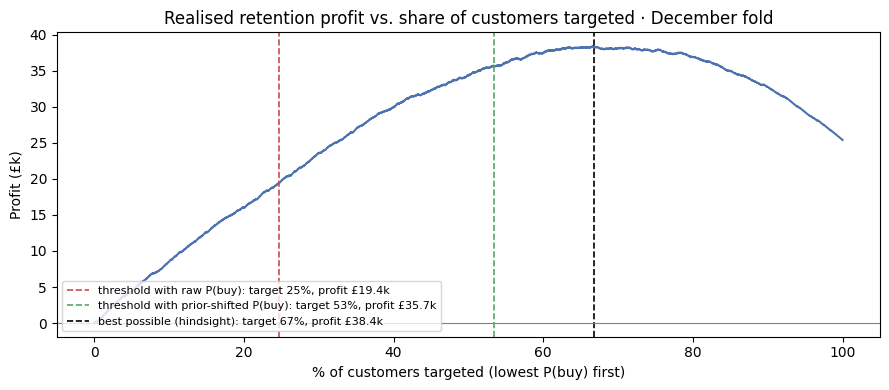

Rule: target if P(buy) < 0.59


In [9]:
C, U, V = 20.0, 0.20, 0.30 * 806
p_star = 1 - C / (U * V)  # target if P(buy) < p_star

d = lr_dec.sort_values("pred").reset_index(drop=True)  # most likely to lapse first
lapse = 1 - d["y"].values
realised = np.cumsum(lapse * U * V - C)  # profit if we target the first k customers
share = np.arange(1, len(d) + 1) / len(d)

k_raw = (d["pred"] < p_star).sum()
k_shift = (d["pred_shifted"] < p_star).sum()
k_best = realised.argmax() + 1

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(share * 100, realised / 1e3, color="#4C72B0")
for k, label, color in [(k_raw, "threshold with raw P(buy)", "#C44E52"), (k_shift, "threshold with prior-shifted P(buy)", "#55A868"),
                        (k_best, "best possible (hindsight)", "black")]:
    ax.axvline(k / len(d) * 100, color=color, ls="--", lw=1.2, label=f"{label}: target {k / len(d):.0%}, profit £{realised[k - 1] / 1e3:.1f}k")
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Realised retention profit vs. share of customers targeted · December fold")
ax.set_xlabel("% of customers targeted (lowest P(buy) first)")
ax.set_ylabel("Profit (£k)")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()
print(f"Rule: target if P(buy) < {p_star:.2f}")

**Takeaways:**
- With **raw** probabilities (too optimistic about buying), the rule targets only 25% of customers and earns about £19k, **half** of what was achievable.
  Miscalibration has a **£ cost**, even though AUC is unaffected.
- With **prior-shifted** probabilities, it targets 53% and earns about £36k, **93% of the hindsight-best** (£38k at 67%). It still under-targets a bit, because the shift under-corrects (section 2).
  (The December shift used an oracle rate; at the test cutoff we'll have a real same-season estimate.)
- The curve is **flat near its peak**, so the exact threshold matters less than being in the right region. That's useful when the cost inputs (c, u, V) are uncertain.

**Caveats, which are the honest part of the story:**
1. **u is an assumption.** The real quantity is *uplift*: how much the offer *changes* behaviour. Ranking by P(lapse) assumes uplift is the same for everyone. It usually isn't (some lapsers can't be saved; some loyal customers buy more with a voucher). The right model is an **uplift model**, trained on an A/B test.
2. **V is the same for everyone here.** Combining P(lapse) with each customer's **own** predicted value (notebook 07) targets high-value at-risk customers first. That's the version for notebook 12.
3. **ARQ version:** offer = FX fee waiver or cashback. c = waived fees, V = 6-month interchange + FX margin, u from a holdout test.

## 5. Summary
| Decision | Choice | Alternative not picked |
|---|---|---|
| Classifier | logistic regression (wins all 4 folds; Dec paired CI excludes 0) | LightGBM: better log loss, worse ranking; re-tested after tuning (08) |
| Imbalance | none (mild) | resampling / class weights: distort probabilities, no ranking gain |
| Calibration | prior-shift to a same-season base rate | isotonic / Platt on recent data: recent data is the wrong season |
| Threshold | from cost: target if P(buy) < 1 − c/(uV) | 0.5: ignores costs; "top X%": ignores who is actually at risk |

In [10]:
out = preds["logistic regression"].rename(columns={"pred": "p_buy_logreg"}).drop(columns="y")
out.to_parquet(Path(CLEAN_PARQUET).parent / "val_preds_buy.parquet", index=False)
print(f"Saved {len(out):,} validation-fold P(buy) predictions for notebook 07's two-part model")

Saved 15,279 validation-fold P(buy) predictions for notebook 07's two-part model


### 🧠 Interpret
1. Check your predictions: did LightGBM win? What average P(buy) did the model predict in December, and why?
2. A stakeholder says: *"AUC is 0.78, so the model's probabilities are good."* Correct them using section 2.
3. Why do the **raw** probabilities make the retention rule target too few customers? Walk through the formula.
4. The prior shift leaves AUC unchanged but fixes the threshold. Explain to a PM why "ranking" and "level" are separate problems, and which one the model solves.
5. **ARQ:** you're asked to target an FX-fee-waiver campaign. What would you need from an A/B test before trusting the "u = 20%" assumption, and how would you use it?